# Reproducing Table 11 and Figure 9 of the paper

This notebook recomputes, from the recorded measurements in this repository,

* **Table 11** – *Results of the experiments beyond 0MA on PostgreSQL, per dataset and query topology*, and
* **Figure 9** – *Median runtimes (log scale) of original queries and rewritings for all 76 rewritten queries*.

These are the only parts of the experimental section that refer to this repository; the other tables and figures belong to the earlier 0MA experiments.

**Input.** Everything is derived from a single file, `benchmarks/results/six-run-timings.csv`: one row per query (204 in total), with the six measured runs of the original query and the six runs of the chosen action. No database is needed. Re-running the queries themselves requires the loaded datasets and the PostgreSQL setup described in `benchmarks/README.md`.

**Requirements.** Python 3 with `pandas`, `numpy` and `matplotlib`. Run the notebook from the repository root (or from `benchmarks/`).

Both the table and the figure are checked against the values printed in the paper at the end of each section.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Locate the data whether the notebook is started from the repository root or from benchmarks/.
DATA = next(p for p in (Path("benchmarks/results/six-run-timings.csv"),
                        Path("results/six-run-timings.csv"),
                        Path("../benchmarks/results/six-run-timings.csv")) if p.exists())

TIMEOUT_S = 60.0                                     # per-execution limit; failed runs are charged this much
RUNS = range(1, 7)                                   # six measured runs (after two warm-ups)
DATASETS = ["STATS", "SNAP", "JOB", "LSQB", "Hetionet"]  # row order of Table 11
TOPOLOGIES = ["acyclic", "cyclic"]

raw = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert len(raw) == 204 and raw.query_id.is_unique
print(f"{len(raw)} queries read from {DATA}")
raw.head()

204 queries read from benchmarks/results/six-run-timings.csv


,query_id,dataset,stratum,selected_action,correctness,shared_native_observation,native_run_1_s_or_status,native_run_2_s_or_status,native_run_3_s_or_status,native_run_4_s_or_status,...,native_run_6_s_or_status,selected_run_1_s_or_status,selected_run_2_s_or_status,selected_run_3_s_or_status,selected_run_4_s_or_status,selected_run_5_s_or_status,selected_run_6_s_or_status,native_median_s,selected_median_s,finite_speedup
0,snap-two-paths-8-cyclic-u3-equality-core,SNAP,cyclic,cost-baseline-v2,unresolved-temp-file-limit,False,60s+,60s+,60s+,60s+,...,60s+,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,,,
1,snap-two-paths-8-acyclic-u3-equality-core,SNAP,acyclic-unguarded,structural-partial-inline-b5,unresolved-temp-file-limit,False,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,...,temp-file-limit,60s+,60s+,60s+,60s+,60s+,60s+,,,
2,hetionet-thesis-cbgigigad-cyclic-g1-equality-core,Hetionet,cyclic,native,identical-source-sql,True,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,...,temp-file-limit,shared native run,shared native run,shared native run,shared native run,shared native run,shared native run,,,
3,hetionet-thesis-cbgigigad-acyclic-u3-equality-...,Hetionet,acyclic-unguarded,native,identical-source-sql,True,temp-file-limit,temp-file-limit,temp-file-limit,temp-file-limit,...,temp-file-limit,shared native run,shared native run,shared native run,shared native run,shared native run,shared native run,,,
4,lsqb-q2-location-cyclic-global-equality-core,LSQB,cyclic,cost-fused-v3,exact-bag,False,11.064907000000002,11.261149,11.273838,11.523062,...,11.689369,11.365091,11.593110000000001,11.587,11.46331,11.427314,12.063688,11.350370999999999,11.525155,0.9848345640470778


## The recorded data

Each `*_run_i_s_or_status` cell holds either the measured time in seconds (planning + execution) or a failure status:

| value | meaning |
| --- | --- |
| a number | completed run, in seconds |
| `60s+` | hit the 60 s statement timeout |
| `temp-file-limit` | aborted by PostgreSQL's `temp_file_limit` (2 GB) |
| `error` | the statement failed |
| `shared native run` | the original query was kept (`selected_action = native`), so no separate run exists |

The column `stratum` gives the topology: `cyclic`, or one of the two acyclic kinds (`acyclic-unguarded`, `continuity-control` = acyclic with global or guarded grouping). Table 11 and Figure 9 only distinguish *acyclic* and *cyclic*.

In [2]:
pd.crosstab(raw.dataset, raw.stratum, margins=True, margins_name="total")

stratum,acyclic-unguarded,continuity-control,cyclic,total
dataset,,,,
Hetionet,6,6,12,24
JOB,18,12,36,66
LSQB,6,6,12,24
SNAP,6,6,12,24
STATS,18,12,36,66
total,54,42,108,204


## Classifying each query

The categories follow the definitions given in the paper's *Results* paragraph:

* **Native kept** – the cost-based decision kept the original query. In parentheses: how many of these did *not* complete all six runs.
* **Rewritten** – a rewriting was chosen. Each rewritten query falls into exactly one of:
  * **Faster / Slower** – *both* versions completed all six runs, and the median runtime of the rewriting is lower / higher;
  * **Rescued** – the original query failed in all six runs (timeout or temp-file limit), while the rewriting completed all six;
  * **Not resolved** – the rewriting did not complete all six runs either.
* **Speedup** – the median, over the Faster and Slower queries, of *median original runtime / median rewriting runtime*.
* **Runtime** – over the rewritten queries, the sum of the median runtimes of the original query and of the rewriting, where every failed run counts as 60 s.

In [3]:
def runs(row, side):
    # The six runs of one side ('native' or 'selected') as seconds; NaN marks a failed run.
    return pd.to_numeric(pd.Series([row[f"{side}_run_{i}_s_or_status"] for i in RUNS]), errors="coerce")


def classify(row):
    native = runs(row, "native")
    q = dict(query_id=row.query_id, dataset=row.dataset,
             topology="cyclic" if row.stratum == "cyclic" else "acyclic",
             rewritten=row.selected_action != "native",
             native_complete=native.notna().all(),
             native_median=native.median() if native.notna().all() else np.nan,
             native_charged=native.fillna(TIMEOUT_S).median(),
             outcome=None, speedup=np.nan)
    if not q["rewritten"]:
        return q
    rewrite = runs(row, "selected")
    q.update(rewrite_complete=rewrite.notna().all(),
             rewrite_median=rewrite.median() if rewrite.notna().all() else np.nan,
             rewrite_charged=rewrite.fillna(TIMEOUT_S).median())
    if q["native_complete"] and q["rewrite_complete"]:
        q["speedup"] = q["native_median"] / q["rewrite_median"]
        q["outcome"] = "faster" if q["speedup"] > 1 else "slower"
    elif not q["rewrite_complete"]:
        q["outcome"] = "not resolved"
    elif native.isna().all():
        q["outcome"] = "rescued"
    else:
        raise ValueError(f"{row.query_id}: original completed only some runs, rewriting all")
    return q


queries = pd.DataFrame([classify(row) for _, row in raw.iterrows()])

# Sanity check: the medians recomputed from the six runs equal the medians stored in the CSV
# (which leaves a median empty unless all six runs completed). For kept queries the CSV repeats
# the native median as selected_median_s, so the rewriting side is only compared for rewritten queries.
for side, col, subset in (("native", "native_median_s", queries.index),
                          ("rewrite", "selected_median_s", queries.index[queries.rewritten])):
    stored = pd.to_numeric(raw[col], errors="coerce")[subset]
    mine = queries[f"{side}_median"][subset]
    both = stored.notna() & mine.notna()
    assert np.allclose(stored[both], mine[both]) and both.sum() == stored.notna().sum()

queries.groupby(["rewritten", "outcome"], dropna=False).size()

rewritten  outcome     
False      NaN             128
True       faster           21
           not resolved     26
           rescued          23
           slower            6
dtype: int64

## Table 11

In [4]:
def summarize(g):
    kept, rw = g[~g.rewritten], g[g.rewritten]
    return {
        "Queries": len(g),
        "Native kept": len(kept),
        "Native kept, incomplete": int((~kept.native_complete).sum()),
        "Rewritten": len(rw),
        "Faster": int((rw.outcome == "faster").sum()),
        "Slower": int((rw.outcome == "slower").sum()),
        "Rescued": int((rw.outcome == "rescued").sum()),
        "Not Resolved": int((rw.outcome == "not resolved").sum()),
        "Speedup": rw.speedup.median(),        # NaN if there is no Faster/Slower query
        "Runtime orig. (s)": rw.native_charged.sum(),
        "Runtime rewr. (s)": rw.rewrite_charged.sum(),
    }


rows, index = [], []
for ds in DATASETS:
    for topo in TOPOLOGIES:
        rows.append(summarize(queries[(queries.dataset == ds) & (queries.topology == topo)]))
        index.append((ds.upper(), topo.capitalize()))
for topo in TOPOLOGIES:
    rows.append(summarize(queries[queries.topology == topo]))
    index.append(("All Datasets", topo.capitalize()))
rows.append(summarize(queries))
index.append(("Total", ""))

table11 = pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(index, names=["Dataset", "Topology"]))


def as_in_paper(t):
    # Same layout as in the paper: "kept (incomplete)", speedup with two decimals, runtimes with one.
    out = t.copy()
    out["Native kept"] = [f"{k} ({i})" for k, i in zip(t["Native kept"], t["Native kept, incomplete"])]
    out["Speedup"] = ["--" if np.isnan(s) else f"{s:.2f}×" for s in t["Speedup"]]
    out["Runtime (s) Orig. → Rewr."] = [f"{o:.1f} → {r:.1f}" for o, r in
                                        zip(t["Runtime orig. (s)"], t["Runtime rewr. (s)"])]
    return out.drop(columns=["Native kept, incomplete", "Runtime orig. (s)", "Runtime rewr. (s)"])


as_in_paper(table11)

Queries Native kept  Rewritten  Faster  Slower  \
Dataset      Topology                                                   
STATS        Acyclic        30      19 (6)         11       5       0   
             Cyclic         36      32 (0)          4       1       3   
SNAP         Acyclic        12       0 (0)         12       0       0   
             Cyclic         12       0 (0)         12       0       0   
JOB          Acyclic        30      25 (4)          5       4       0   
             Cyclic         36      26 (0)         10      10       0   
LSQB         Acyclic        12       5 (5)          7       0       0   
             Cyclic         12       8 (4)          4       1       3   
HETIONET     Acyclic        12       3 (3)          9       0       0   
             Cyclic         12      10 (5)          2       0       0   
All Datasets Acyclic        96     52 (18)         44       9       0   
             Cyclic        108      76 (9)         32      12       6   
Total                      204    128 (27)         76      21       6   

                       Rescued  Not Resolved Speedup Runtime (s) Orig. → Rewr.  
Dataset      Topology                                                           
STATS        Acyclic         5             1  10.44×              417.1 → 94.4  
             Cyclic          0             0   0.94×               44.7 → 51.1  
SNAP         Acyclic         5             7      --             720.0 → 429.9  
             Cyclic          0            12      --             720.0 → 720.0  
JOB          Acyclic         1             0  27.07×                98.5 → 1.2  
             Cyclic          0             0   6.12×                 3.2 → 0.8  
LSQB         Acyclic         2             5      --             420.0 → 396.7  
             Cyclic          0             0   0.99×               62.4 → 62.6  
HETIONET     Acyclic         9             0      --              540.0 → 73.2  
             Cyclic          1             1      --              120.0 → 63.4  
All Datasets Acyclic        22            13  12.27×            2195.6 → 995.4  
             Cyclic          1            13   2.29×             950.2 → 897.9  
Total                       23            26   6.87×           3145.9 → 1893.3

### Check against the paper

The values below are copied from Table 11 of the paper (speedups rounded to two decimals, runtimes to one).

In [5]:
PAPER_TABLE11 = [
    # queries, kept, (incomplete), rewritten, faster, slower, rescued, not resolved, speedup, orig. s, rewr. s
    (30, 19, 6, 11, 5, 0, 5, 1, 10.44, 417.1, 94.4),     # STATS     acyclic
    (36, 32, 0, 4, 1, 3, 0, 0, 0.94, 44.7, 51.1),        # STATS     cyclic
    (12, 0, 0, 12, 0, 0, 5, 7, None, 720.0, 429.9),      # SNAP      acyclic
    (12, 0, 0, 12, 0, 0, 0, 12, None, 720.0, 720.0),     # SNAP      cyclic
    (30, 25, 4, 5, 4, 0, 1, 0, 27.07, 98.5, 1.2),        # JOB       acyclic
    (36, 26, 0, 10, 10, 0, 0, 0, 6.12, 3.2, 0.8),        # JOB       cyclic
    (12, 5, 5, 7, 0, 0, 2, 5, None, 420.0, 396.7),       # LSQB      acyclic
    (12, 8, 4, 4, 1, 3, 0, 0, 0.99, 62.4, 62.6),         # LSQB      cyclic
    (12, 3, 3, 9, 0, 0, 9, 0, None, 540.0, 73.2),        # HETIONET  acyclic
    (12, 10, 5, 2, 0, 0, 1, 1, None, 120.0, 63.4),       # HETIONET  cyclic
    (96, 52, 18, 44, 9, 0, 22, 13, 12.27, 2195.6, 995.4),  # all     acyclic
    (108, 76, 9, 32, 12, 6, 1, 13, 2.29, 950.2, 897.9),    # all     cyclic
    (204, 128, 27, 76, 21, 6, 23, 26, 6.87, 3145.9, 1893.3),  # total
]

for (label, row), expected in zip(table11.iterrows(), PAPER_TABLE11):
    *counts, speedup, orig, rewr = expected
    assert list(row.iloc[:8].astype(int)) == counts, label
    assert (np.isnan(row["Speedup"]) and speedup is None) or round(row["Speedup"], 2) == speedup, label
    assert round(row["Runtime orig. (s)"], 1) == orig and round(row["Runtime rewr. (s)"], 1) == rewr, label
print("Table 11: all 13 rows match the paper.")

Table 11: all 13 rows match the paper.


The numbers quoted in the paper's text also follow from the same data:

In [6]:
both = queries[queries.outcome.isin(["faster", "slower"])]
worst = both.loc[both.speedup.idxmin()]
acyc = both[both.topology == "acyclic"]
print(f"largest slowdown: factor {1 / worst.speedup:.2f} "
      f"({worst.native_median:.1f}s -> {worst.rewrite_median:.1f}s, {worst.query_id})")
print(f"acyclic, both completed: median speedup {acyc.speedup.median():.2f} "
      f"(between {acyc.speedup.min():.2f} and {acyc.speedup.max():.2f})")
cyc = both[(both.topology == "cyclic") & both.dataset.isin(["STATS", "LSQB"])]
print(f"cyclic STATS and LSQB: factors between {cyc.speedup.min():.2f} and {cyc.speedup.max():.2f}")
print(f"cyclic JOB: median speedup {both[(both.topology == 'cyclic') & (both.dataset == 'JOB')].speedup.median():.2f}")
print("rewritten queries where the original completed but the rewriting did not:",
      int((queries.rewritten & queries.native_complete & ~queries.rewrite_complete.fillna(True).astype(bool)).sum()))

largest slowdown: factor 1.29 (14.0s -> 18.1s, fresh-stats-q027-cyclic-u2-equality-core)
acyclic, both completed: median speedup 12.27 (between 7.15 and 95.33)
cyclic STATS and LSQB: factors between 0.78 and 1.06
cyclic JOB: median speedup 6.12
rewritten queries where the original completed but the rewriting did not: 0


## Figure 9

All 76 rewritten queries, with the median runtime of the original query on the x-axis and of the chosen rewriting on the y-axis (log scale). A version that did not complete all six runs is placed at "fail" (plotted at 150 s). The 26 queries for which neither version completed would all sit on the single point (fail, fail); as in the paper they are spread out on a grid in the shaded upper-right corner, so their position there carries no meaning.

The paper draws the figure with pgfplots; here it is redrawn with matplotlib using the same markers, colours, axes and point positions.

76 rewritten queries, 26 of them with neither version completing


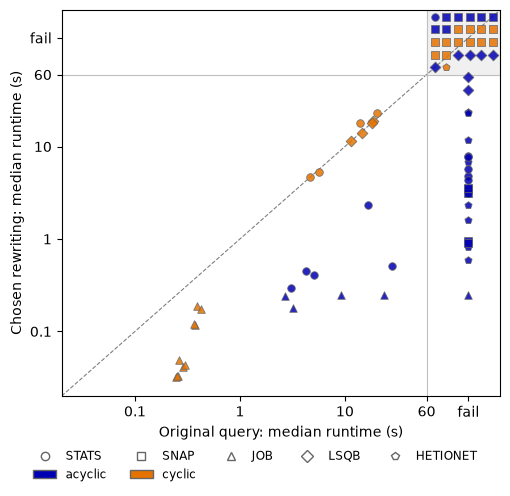

In [7]:
FAIL = 150.0
MARKERS = {"STATS": "o", "SNAP": "s", "JOB": "^", "LSQB": "D", "Hetionet": "p"}   # pgfplots: *, square*, triangle*, diamond*, pentagon*
COLOURS = {"acyclic": (0.0, 0.0, 0.7), "cyclic": (0.9, 0.45, 0.0)}                 # blue!70!black, orange!90!black

rw = queries[queries.rewritten].copy()
rw["x"] = rw.native_median.fillna(FAIL)
rw["y"] = rw.rewrite_median.fillna(FAIL)
rw["series"] = rw.dataset.map(DATASETS.index) * 2 + rw.topology.map(TOPOLOGIES.index)   # dataset, then topology

# Neither version completed: lay these out on a 6 x 5 grid, evenly spaced on the log scale
# (x from 72 to 255 left to right, y from 255 to 72 top to bottom), filled row by row in series order.
corner = (rw.x == FAIL) & (rw.y == FAIL)
order = rw[corner].sort_values("series", kind="stable").index
grid_x = 72 * (255 / 72) ** (np.arange(6) / 5)
grid_y = 255 * (72 / 255) ** (np.arange(5) / 4)
for k, i in enumerate(order):
    rw.loc[i, ["x", "y"]] = grid_x[k % 6], grid_y[k // 6]
print(f"{len(rw)} rewritten queries, {corner.sum()} of them with neither version completing")

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.set(xscale="log", yscale="log", xlim=(0.02, 300), ylim=(0.02, 300),
       xlabel="Original query: median runtime (s)", ylabel="Chosen rewriting: median runtime (s)")
ticks, labels = [0.1, 1, 10, 60, 150], ["0.1", "1", "10", "60", "fail"]
ax.set_xticks(ticks, labels); ax.set_yticks(ticks, labels)
ax.minorticks_off()
ax.fill_between([60, 300], 60, 300, color="0.94", zorder=0)
ax.plot([0.02, 300], [0.02, 300], ls="--", color="0.5", lw=0.8, zorder=1)
ax.axvline(60, color="0.75", lw=0.8, zorder=1); ax.axhline(60, color="0.75", lw=0.8, zorder=1)
for (ds, topo), g in rw.groupby(["dataset", "topology"]):
    ax.scatter(g.x, g.y, marker=MARKERS[ds], s=30, facecolor=COLOURS[topo], edgecolor="0.4",
               linewidth=0.6, alpha=0.85, zorder=2)

# Legend as in the paper: datasets in the first row, topologies in the second
# (matplotlib fills legend columns top to bottom, hence the interleaving with blank entries).
first = [Line2D([], [], ls="", marker=MARKERS[ds], markerfacecolor="white", markeredgecolor="0.4",
                label=ds.upper()) for ds in DATASETS]
second = [Patch(facecolor=COLOURS[t], edgecolor="0.4", label=t) for t in TOPOLOGIES]
second += [Line2D([], [], ls="", label=" ")] * (len(first) - len(second))
handles = [h for pair in zip(first, second) for h in pair]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize="small", frameon=False, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()

### Check against the paper

The paper's figure is a pgfplots `\addplot ... coordinates {...}` per dataset/topology series, with values rounded to four significant digits. The cell below prints the coordinates computed here in the same format and compares them with the ones in the paper's source.

In [8]:
def coords(points):
    return " ".join(f"({x:.4g},{y:.4g})" for x, y in points)

# Points outside the corner, in the order of the CSV, per series.
computed = {(ds, topo): coords(zip(g.x, g.y))
            for (ds, topo), g in rw[~corner].groupby(["dataset", "topology"], sort=False)}
for ds in DATASETS:
    for topo in TOPOLOGIES:
        if (ds, topo) in computed:
            print(f"{ds:>8} {topo:<7} {computed[ds, topo]}")

PAPER_FIGURE9 = {
    ("STATS", "acyclic"): "(150,4.781) (5.046,0.4113) (150,7.876) (3.072,0.2943) (28,0.5155) (150,5.7) (16.73,2.34) (150,4.345) (150,7.694) (4.213,0.4509)",
    ("STATS", "cyclic"): "(14.02,18.06) (5.642,5.298) (20.31,23.02) (4.687,4.721)",
    ("SNAP", "acyclic"): "(150,3.448) (150,0.953) (150,0.9094) (150,3.179) (150,3.521)",
    ("JOB", "acyclic"): "(150,0.2496) (23.54,0.2469) (2.713,0.2429) (3.203,0.1791) (9.092,0.2508)",
    ("JOB", "cyclic"): "(0.3752,0.1172) (0.2639,0.04924) (0.3629,0.1188) (0.3923,0.1871) (0.2553,0.03254) (0.2459,0.03214) (0.2879,0.04162) (0.2519,0.03254) (0.2997,0.04361) (0.4282,0.173)",
    ("LSQB", "acyclic"): "(150,40.48) (150,56.24)",
    ("LSQB", "cyclic"): "(11.35,11.53) (18.58,18.83) (18.05,18.09) (14.44,14.15)",
    ("Hetionet", "acyclic"): "(150,6.839) (150,23.43) (150,22.79) (150,1.597) (150,0.5942) (150,0.814) (150,2.335) (150,3.03) (150,11.82)",
    ("Hetionet", "cyclic"): "(150,3.37)",
}
# The 26 (fail, fail) points: series and grid position, in the paper's order.
PAPER_CORNER = [
    ("STATS", "acyclic", "(72,255)"),
    ("SNAP", "acyclic", "(92.72,255) (119.4,255) (153.8,255) (198,255) (255,255) (72,185.9) (92.72,185.9)"),
    ("SNAP", "cyclic", "(119.4,185.9) (153.8,185.9) (198,185.9) (255,185.9) (72,135.5) (92.72,135.5) (119.4,135.5) "
                       "(153.8,135.5) (198,135.5) (255,135.5) (72,98.77) (92.72,98.77)"),
    ("LSQB", "acyclic", "(119.4,98.77) (153.8,98.77) (198,98.77) (255,98.77) (72,72)"),
    ("Hetionet", "cyclic", "(92.72,72)"),
]

assert computed == PAPER_FIGURE9
c = rw.loc[order]
assert [(ds, topo, coords(zip(g.x, g.y))) for (ds, topo), g in c.groupby(["dataset", "topology"], sort=False)] == PAPER_CORNER
print("\nFigure 9: all 76 points match the coordinates in the paper.")

   STATS acyclic (150,4.781) (5.046,0.4113) (150,7.876) (3.072,0.2943) (28,0.5155) (150,5.7) (16.73,2.34) (150,4.345) (150,7.694) (4.213,0.4509)
   STATS cyclic  (14.02,18.06) (5.642,5.298) (20.31,23.02) (4.687,4.721)
    SNAP acyclic (150,3.448) (150,0.953) (150,0.9094) (150,3.179) (150,3.521)
     JOB acyclic (150,0.2496) (23.54,0.2469) (2.713,0.2429) (3.203,0.1791) (9.092,0.2508)
     JOB cyclic  (0.3752,0.1172) (0.2639,0.04924) (0.3629,0.1188) (0.3923,0.1871) (0.2553,0.03254) (0.2459,0.03214) (0.2879,0.04162) (0.2519,0.03254) (0.2997,0.04361) (0.4282,0.173)
    LSQB acyclic (150,40.48) (150,56.24)
    LSQB cyclic  (11.35,11.53) (18.58,18.83) (18.05,18.09) (14.44,14.15)
Hetionet acyclic (150,6.839) (150,23.43) (150,22.79) (150,1.597) (150,0.5942) (150,0.814) (150,2.335) (150,3.03) (150,11.82)
Hetionet cyclic  (150,3.37)

Figure 9: all 76 points match the coordinates in the paper.
